In [ ]:
#In this notebook we will do attention(predicitng next word )



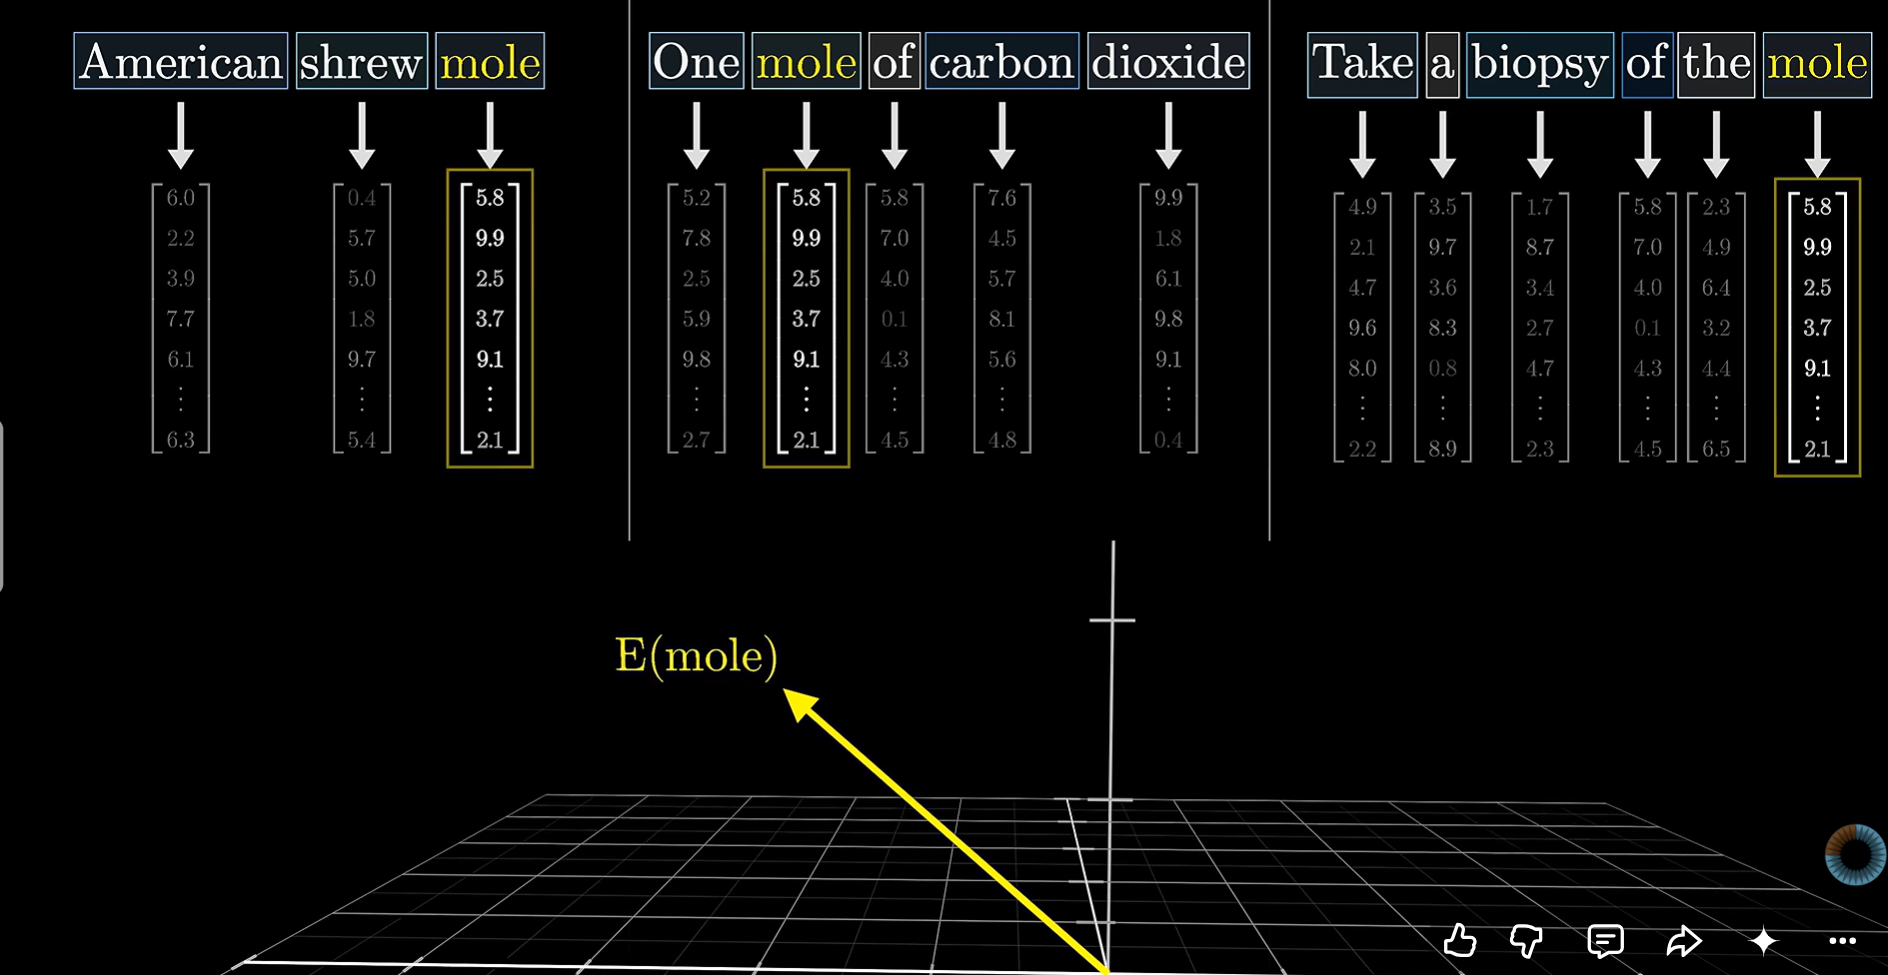

In the above image, all three "mole" tokens start with the same static embedding because they map to the same entry in the embedding table. Self-attention then updates each one using the surrounding sentence so each "mole" gets a different contextual representation.

In [ ]:
import torch
import torch.nn.functional as F

torch.manual_seed(42)

# Batch size, number of heads, sequence length, head dimension
B = 1
H = 1
T = 4
D = 8

# Generate Q, K, V
Q = torch.randn(B, H, T, D)
K = torch.randn(B, H, T, D)
V = torch.randn(B, H, T, D)


#scaled  product attention
output = F.scaled_dot_product_attention(
    Q, K, V,
    is_causal=True
)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)
print("Output shape:", output.shape)


Q shape: torch.Size([1, 1, 4, 8])
K shape: torch.Size([1, 1, 4, 8])
V shape: torch.Size([1, 1, 4, 8])
Output shape: torch.Size([1, 1, 4, 8])


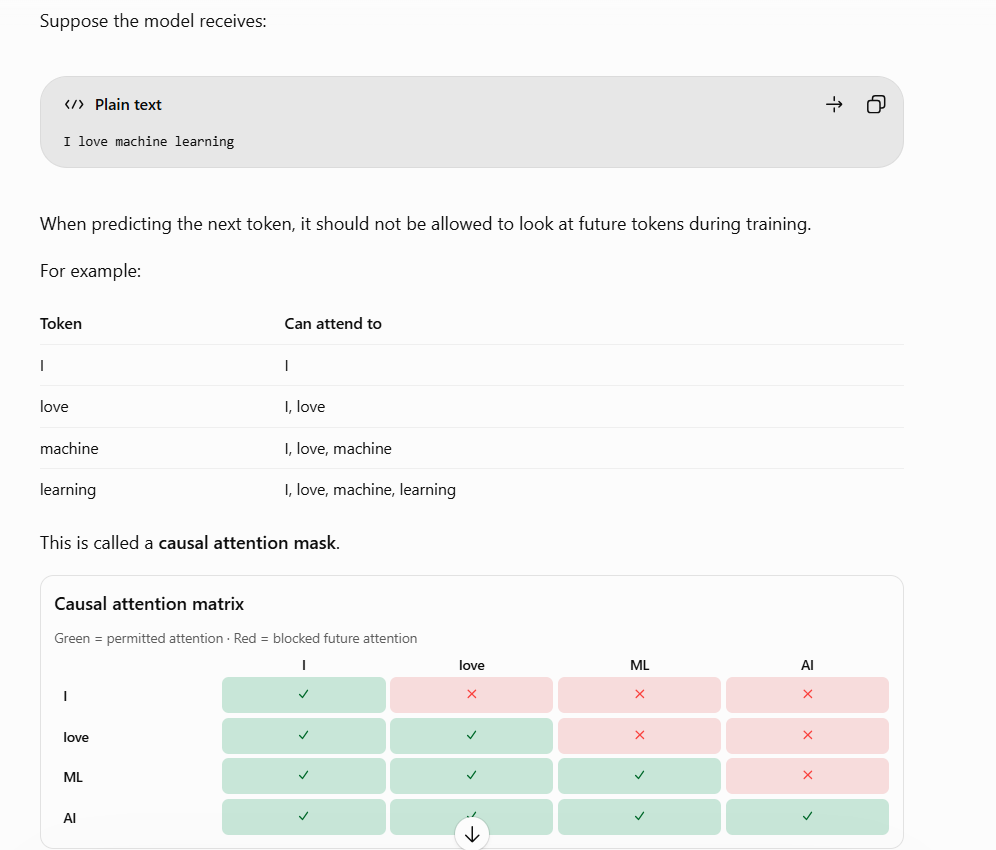

In [ ]:
#let's inspect attention in a real pretrained gpt -2 model
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

name = "distilgpt2"

tokenizer = AutoTokenizer.from_pretrained(name)
model = AutoModelForCausalLM.from_pretrained(
    name,
    attn_implementation="eager"
)

model.eval()

text = "The cat drank milk because it was thirsty."

inputs = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(
        **inputs,
        output_attentions=True
    )

print("Number of attention layers:", len(outputs.attentions))

for i, attention in enumerate(outputs.attentions):
    print(f"Layer {i}: {attention.shape}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Number of attention layers: 6
Layer 0: torch.Size([1, 12, 9, 9])
Layer 1: torch.Size([1, 12, 9, 9])
Layer 2: torch.Size([1, 12, 9, 9])
Layer 3: torch.Size([1, 12, 9, 9])
Layer 4: torch.Size([1, 12, 9, 9])
Layer 5: torch.Size([1, 12, 9, 9])


In [ ]:
print("Number of heads:", model.config.n_head)
print("Hidden size:", model.config.n_embd)
print("Number of layers:", model.config.n_layer)
print(outputs.attentions[0][0, 0])

Number of heads: 12
Hidden size: 768
Number of layers: 6
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.6121, 0.3879, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2673, 0.2633, 0.4694, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3777, 0.3831, 0.0984, 0.1408, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2826, 0.1379, 0.1633, 0.3041, 0.1120, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3251, 0.2602, 0.1369, 0.1397, 0.0911, 0.0470, 0.0000, 0.0000, 0.0000],
        [0.2420, 0.0617, 0.3395, 0.0616, 0.0813, 0.0441, 0.1697, 0.0000, 0.0000],
        [0.0991, 0.1567, 0.1792, 0.2285, 0.0176, 0.0137, 0.0543, 0.2510, 0.0000],
        [0.2936, 0.1159, 0.1212, 0.0497, 0.1298, 0.0670, 0.0333, 0.1771, 0.0124]])
